## split data diawal

In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('../data/raw/Raw-Final-Rumah.csv')

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(train_df.shape, test_df.shape)

(32160, 8) (8040, 8)


## EDA

In [42]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32160 entries, 0 to 32159
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Harga          32160 non-null  str  
 1   Kamar Tidur    32151 non-null  str  
 2   Kamar Mandi    28640 non-null  str  
 3   Garasi         28026 non-null  str  
 4   Luas Tanah     26019 non-null  str  
 5   Luas Bangunan  19741 non-null  str  
 6   Kecamatan      32160 non-null  str  
 7   Page           32160 non-null  int64
dtypes: int64(1), str(7)
memory usage: 2.0 MB


In [43]:
train_df.head(10)

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
0,425 Juta,3,1,1,LT : 60 m²,LB : 39 m²,Beji,1801
1,"8,2 Miliar",4,3,3,LT : 216 m²,LB : 283 m²,Cimanggis,1905
2,"1,33 Miliar",4,2,LT:98 m²,LB : 95 m²,NaN,Sukmajaya,7
3,"2,68 Miliar",3,3,2,LT : 119 m²,LB : 128 m²,Cimanggis,152
4,999 Juta,3,2,1,LT : 72 m²,LB : 90 m²,Bojong Sari,548
5,871 Juta,3,2,1,LT : 67 m²,LB : 54 m²,Mekarsari,1951
6,299 Juta,2,1,LB:35 m²,NaN,NaN,Cimanggis,1921
7,"1,19 Miliar",3,2,2,LT : 117 m²,LB : 90 m²,Cilodong,701
8,"2,3 Miliar Total",LT:500 m²,NaN,NaN,NaN,NaN,Cibubur,189
9,"1,8 Miliar",8,3,LT:443 m²,LB : 200 m²,NaN,Sukmajaya,1687


In [44]:
train_df.isnull().sum()

Harga                0
Kamar Tidur          9
Kamar Mandi       3520
Garasi            4134
Luas Tanah        6141
Luas Bangunan    12419
Kecamatan            0
Page                 0
dtype: int64

In [45]:
train_df.duplicated().sum()

np.int64(1077)

# check salah kolom Lt

In [46]:
for col in train_df.columns[:-1]:  # exclude Page
    mask = train_df[col].astype(str).str.contains('LT|LB', case=False, na=False)
    print(col, mask.sum())

Harga 0
Kamar Tidur 3934
Kamar Mandi 1700
Garasi 8276
Luas Tanah 26019
Luas Bangunan 19741
Kecamatan 0


In [47]:
cols_prefix = ['Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan']
for col in cols_prefix:
    print(f'--- {col} (prefix) ---')
    print(train_df[col].astype(str).str.extract(r'^([A-Za-z]*)', expand=False).value_counts())
    print()

print('--- Harga (suffix) ---')
print(train_df['Harga'].astype(str).str.extract(r'([A-Za-z]+)$', expand=False).value_counts())
print()

print('--- Kecamatan (sample unique) ---')
print(train_df['Kecamatan'].nunique())
print(train_df['Kecamatan'].unique()[:30])

--- Kamar Tidur (prefix) ---
Kamar Tidur
      28217
LT     3861
LB       73
Name: count, dtype: int64

--- Kamar Mandi (prefix) ---
Kamar Mandi
      26940
LT     1090
LB      610
Name: count, dtype: int64

--- Garasi (prefix) ---
Garasi
      19750
LT     6281
LB     1995
Name: count, dtype: int64

--- Luas Tanah (prefix) ---
Luas Tanah
LT    19743
LB     6276
Name: count, dtype: int64

--- Luas Bangunan (prefix) ---
Luas Bangunan
LB    19741
Name: count, dtype: int64

--- Harga (suffix) ---
Harga
Miliar     16179
Juta       11148
Total       4743
Agen          30
Ribu          11
Triliun        6
Name: count, dtype: int64

--- Kecamatan (sample unique) ---
38
<StringArray>
[          'Beji',      'Cimanggis',      'Sukmajaya',    'Bojong Sari',
      'Mekarsari',       'Cilodong',        'Cibubur',       'Cinangka',
         'Cinere',     'Tanah Baru',           'Limo',       'Sawangan',
        'Citayam',      'Cilangkap',   'Pancoran Mas',       'Cipayung',
       'Margonda',     

In [48]:
print(train_df[train_df['Harga'].str.contains('Total', na=False)]['Harga'].head(10).tolist())
print()
print(train_df[train_df['Harga'].str.contains('Agen', na=False)]['Harga'].head(10).tolist())
print()
print(train_df[train_df['Harga'].str.contains('Ribu', na=False)]['Harga'].head(5).tolist())
print()
print(train_df[train_df['Harga'].str.contains('Triliun', na=False)]['Harga'].head(5).tolist())

['2,3 Miliar Total', '38 Miliar Total', '1,15 Miliar Total', '800 Juta Total', '470 Juta Total', '8,1 Miliar Total', '5,5 Miliar Total', '5,67 Miliar Total', '5,5 Miliar Total', '15 Miliar Total']

['Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen', 'Hubungi Agen']

['3,5 Ribu', '893 Ribu', '735 Ribu', '422 Ribu', '900 Ribu']

['19,8 Triliun Total', '93,1 Triliun Total', '27 Triliun Total', '36,3 Triliun Total', '3,8 Triliun Total']


# fix harga

In [49]:
mask_other = ~train_df['Harga'].str.contains('Miliar|Juta|Total|Agen|Ribu|Triliun', na=False)
print(mask_other.sum())
print(train_df.loc[mask_other, 'Harga'].unique()[:30])

0
<StringArray>
[]
Length: 0, dtype: str


In [50]:
mask_per_m2 = train_df['Harga'].str.contains('/m²|/m2', na=False)
print(mask_per_m2.sum())
print(train_df.loc[mask_per_m2, 'Harga'].unique()[:20])

43
<StringArray>
[     '7 Juta /m²',      '5 Juta /m²',    '3 Miliar /m²',    '5,3 Juta /m²',
   '5,35 Juta /m²',  '3,5 Miliar /m²',    '4,5 Juta /m²',  '1,5 Miliar /m²',
     '13 Juta /m²',     '22 Juta /m²',    '2,8 Juta /m²',  '3,9 Miliar /m²',
  '1,9 Miliar /m²',    '160 Juta /m²',     '19 Juta /m²',     '10 Juta /m²',
   '11 Miliar /m²',    '5,5 Juta /m²',    '6,5 Juta /m²', '8,95 Miliar /m²']
Length: 20, dtype: str


In [51]:
# Drop baris tanpa harga valid / basis beda
train_df = train_df[~train_df['Harga'].str.contains('Agen|Ribu|Triliun|/m²|/m2', na=False)].copy()

# Parse harga ke rupiah
def parse_harga(x):
    x = x.replace('Total', '').strip()
    x = x.replace('Miliar', '').replace('Juta', 'JT').strip()
    if 'JT' in x:
        num = x.replace('JT', '').replace(',', '.').strip()
        return float(num) * 1_000_000
    else:
        num = x.replace(',', '.').strip()
        return float(num) * 1_000_000_000

train_df['Harga_num'] = train_df['Harga'].apply(parse_harga)
train_df[['Harga', 'Harga_num']].head(10)

,Harga,Harga_num
0,425 Juta,4.250000e+08
1,"8,2 Miliar",8.200000e+09
2,"1,33 Miliar",1.330000e+09
3,"2,68 Miliar",2.680000e+09
4,999 Juta,9.990000e+08
5,871 Juta,8.710000e+08
6,299 Juta,2.990000e+08
7,"1,19 Miliar",1.190000e+09
8,"2,3 Miliar Total",2.300000e+09
9,"1,8 Miliar",1.800000e+09


# checkingn kolom selain harga

In [52]:
cek = train_df[['Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan']].astype(str).fillna('')

def get_order(row):
    tags = []
    for v in row:
        if v.startswith('LT'):
            tags.append('LT')
        elif v.startswith('LB'):
            tags.append('LB')
    return tuple(tags)

orders = cek.apply(get_order, axis=1)
print(orders.value_counts())

(LT, LB)    27469
(LT,)        3372
(LB,)        1165
()             17
Name: count, dtype: int64


In [53]:
import re

def extract_row(row):
    numbers = []
    lt_val = None
    lb_val = None
    for v in row:
        if pd.isna(v):
            continue
        v = str(v).strip()
        if v.startswith('LT'):
            m = re.search(r'(\d+)', v)
            if m:
                lt_val = int(m.group(1))
        elif v.startswith('LB'):
            m = re.search(r'(\d+)', v)
            if m:
                lb_val = int(m.group(1))
        else:
            m = re.search(r'(\d+)', v)
            if m:
                numbers.append(int(m.group(1)))
    kt = numbers[0] if len(numbers) > 0 else None
    km = numbers[1] if len(numbers) > 1 else None
    gr = numbers[2] if len(numbers) > 2 else None
    return pd.Series([kt, km, gr, lt_val, lb_val])

cols5 = ['Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan']
train_df[['KT_fix','KM_fix','Garasi_fix','LT_fix','LB_fix']] = train_df[cols5].apply(extract_row, axis=1)

train_df[cols5 + ['KT_fix','KM_fix','Garasi_fix','LT_fix','LB_fix']].head(15)

,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,KT_fix,KM_fix,Garasi_fix,LT_fix,LB_fix
0,3,1,1,LT : 60 m²,LB : 39 m²,3.0,1.0,1.0,60.0,39.0
1,4,3,3,LT : 216 m²,LB : 283 m²,4.0,3.0,3.0,216.0,283.0
2,4,2,LT:98 m²,LB : 95 m²,NaN,4.0,2.0,NaN,98.0,95.0
3,3,3,2,LT : 119 m²,LB : 128 m²,3.0,3.0,2.0,119.0,128.0
4,3,2,1,LT : 72 m²,LB : 90 m²,3.0,2.0,1.0,72.0,90.0
5,3,2,1,LT : 67 m²,LB : 54 m²,3.0,2.0,1.0,67.0,54.0
6,2,1,LB:35 m²,NaN,NaN,2.0,1.0,NaN,NaN,35.0
7,3,2,2,LT : 117 m²,LB : 90 m²,3.0,2.0,2.0,117.0,90.0
8,LT:500 m²,NaN,NaN,NaN,NaN,NaN,NaN,NaN,500.0,NaN
9,8,3,LT:443 m²,LB : 200 m²,NaN,8.0,3.0,NaN,443.0,200.0


In [54]:
train_df = train_df.drop(columns=['Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan'])
train_df = train_df.rename(columns={
    'KT_fix': 'Kamar Tidur',
    'KM_fix': 'Kamar Mandi',
    'Garasi_fix': 'Garasi',
    'LT_fix': 'Luas Tanah',
    'LB_fix': 'Luas Bangunan'
})

train_df.isnull().sum()

Harga                0
Kecamatan            0
Page                 0
Harga_num            0
Kamar Tidur       3852
Kamar Mandi       5097
Garasi           12281
Luas Tanah        1182
Luas Bangunan     3389
dtype: int64

# cek duplikat

In [55]:
train_df = train_df.reset_index(drop=True)
print(train_df.duplicated().sum())
print(train_df.shape)

1077
(32023, 9)


In [56]:
dup_partial = train_df.duplicated(subset=['Harga_num','Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan'])
print(dup_partial.sum())
train_df[dup_partial].head(10)

9077


,Harga,Kecamatan,Page,Harga_num,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan
309,4 Miliar,Cimanggis,933,4.000000e+09,4.0,2.0,NaN,400.0,250.0
336,750 Juta,Rangkapanjaya,1143,7.500000e+08,2.0,1.0,1.0,75.0,60.0
354,395 Juta,Cipayung,192,3.950000e+08,3.0,1.0,1.0,65.0,36.0
417,"1,2 Miliar",Cinere,1918,1.200000e+09,4.0,3.0,1.0,106.0,100.0
436,365 Juta,Cinere,629,3.650000e+08,2.0,1.0,1.0,71.0,40.0
478,"1,2 Miliar",Cinere,616,1.200000e+09,3.0,2.0,1.0,60.0,90.0
508,6 Miliar Total,Tapos,1745,6.000000e+09,NaN,NaN,NaN,663.0,NaN
544,"1,4 Miliar",Cimanggis,1514,1.400000e+09,2.0,1.0,1.0,90.0,70.0
582,"1,8 Miliar Total",Sawangan,1199,1.800000e+09,NaN,NaN,NaN,509.0,NaN
679,"9,6 Miliar",Depok I,333,9.600000e+09,9.0,6.0,NaN,805.0,450.0


In [57]:
train_df = train_df.drop_duplicates().reset_index(drop=True)
print(train_df.shape)

(30946, 9)


# check kecamatan

In [58]:
print(train_df['Kecamatan'].nunique())
print(train_df['Kecamatan'].value_counts())

38
Kecamatan
Cinere              6699
Sawangan            3523
Cimanggis           2356
Pancoran Mas        1808
Cilodong            1579
Beji                1462
Sukmajaya           1293
Limo                1131
Depok I             1091
Margonda            1080
Cibubur             1075
Tapos                878
Bojong Sari          819
Citayam              737
Cipayung             633
Pangkalan Jati       581
Depok II             562
Harjamukti           528
Cinangka             490
Tanah Baru           385
Rangkapanjaya        305
Kukusan              292
Gandul               279
Kelapa Dua           266
Krukut               202
Pasir Putih          183
Cisalak              161
Cilangkap            118
Mekarsari            108
Sukatani              94
Tugu                  71
Grand Depok City      65
Tirtajaya             60
Studio Alam           11
Ciangsana             10
Kalimanggis            7
Babadan                3
Sumur Batu             1
Name: count, dtype: int64


# mapping kecamatan

In [59]:
kec_map = {
    'Rangkapanjaya': 'Pancoran Mas', 'Depok I': 'Pancoran Mas', 'Depok II': 'Pancoran Mas',
    'Margonda': 'Pancoran Mas',
    'Harjamukti': 'Cimanggis', 'Cibubur': 'Cimanggis', 'Mekarsari': 'Cimanggis',
    'Tugu': 'Cimanggis', 'Kelapa Dua': 'Cimanggis', 'Cisalak': 'Cimanggis',
    'Tirtajaya': 'Sukmajaya', 'Studio Alam': 'Sukmajaya', 'Grand Depok City': 'Sukmajaya',
    'Tanah Baru': 'Beji', 'Kukusan': 'Beji',
    'Pangkalan Jati': 'Limo', 'Krukut': 'Limo',
    'Cilangkap': 'Tapos', 'Sukatani': 'Tapos',
    'Cinangka': 'Sawangan', 'Pasir Putih': 'Sawangan',
    'Gandul': 'Cinere',
    'Citayam': 'Cipayung',
}

train_df['Kecamatan'] = train_df['Kecamatan'].replace(kec_map)

out_of_scope = ['Ciangsana', 'Kalimanggis', 'Babadan', 'Sumur Batu']
train_df = train_df[~train_df['Kecamatan'].isin(out_of_scope)].reset_index(drop=True)

print(train_df['Kecamatan'].nunique())
print(train_df['Kecamatan'].value_counts())

11
Kecamatan
Cinere          6978
Pancoran Mas    4846
Cimanggis       4565
Sawangan        4196
Beji            2139
Limo            1914
Cilodong        1579
Sukmajaya       1429
Cipayung        1370
Tapos           1090
Bojong Sari      819
Name: count, dtype: int64


# checking page

In [60]:
train_df[['Page','Harga_num']].corr()

,Page,Harga_num
Page,1.000000,0.003401
Harga_num,0.003401,1.000000


# drop kolom page

In [61]:
train_df = train_df.drop(columns=['Page'])
train_df.columns.tolist()

['Harga',
 'Kecamatan',
 'Harga_num',
 'Kamar Tidur',
 'Kamar Mandi',
 'Garasi',
 'Luas Tanah',
 'Luas Bangunan']

In [62]:
train_df.head(10)

,Harga,Kecamatan,Harga_num,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan
0,425 Juta,Beji,4.250000e+08,3.0,1.0,1.0,60.0,39.0
1,"8,2 Miliar",Cimanggis,8.200000e+09,4.0,3.0,3.0,216.0,283.0
2,"1,33 Miliar",Sukmajaya,1.330000e+09,4.0,2.0,NaN,98.0,95.0
3,"2,68 Miliar",Cimanggis,2.680000e+09,3.0,3.0,2.0,119.0,128.0
4,999 Juta,Bojong Sari,9.990000e+08,3.0,2.0,1.0,72.0,90.0
5,871 Juta,Cimanggis,8.710000e+08,3.0,2.0,1.0,67.0,54.0
6,299 Juta,Cimanggis,2.990000e+08,2.0,1.0,NaN,NaN,35.0
7,"1,19 Miliar",Cilodong,1.190000e+09,3.0,2.0,2.0,117.0,90.0
8,"2,3 Miliar Total",Cimanggis,2.300000e+09,NaN,NaN,NaN,500.0,NaN
9,"1,8 Miliar",Sukmajaya,1.800000e+09,8.0,3.0,NaN,443.0,200.0


# check outlier

In [63]:
train_df[['Harga_num','Luas Tanah','Luas Bangunan']].describe()

,Harga_num,Luas Tanah,Luas Bangunan
count,3.092500e+04,2.977400e+04,2.768000e+04
mean,5.071643e+09,2.815609e+04,3.344888e+04
std,2.902541e+10,4.745263e+06,4.958023e+06
min,1.030000e+06,1.000000e+00,1.000000e+00
25%,7.800000e+08,7.200000e+01,6.000000e+01
50%,1.500000e+09,1.190000e+02,1.010000e+02
75%,3.400000e+09,2.850000e+02,2.000000e+02
max,9.960000e+11,8.188011e+08,8.188011e+08


In [64]:
print(train_df.nlargest(5, 'Luas Tanah')[['Harga','Harga_num','Luas Tanah','Luas Bangunan','Kecamatan']])
print()
print(train_df.nlargest(5, 'Harga_num')[['Harga','Harga_num','Luas Tanah','Luas Bangunan','Kecamatan']])
print()
print(train_df.nsmallest(5, 'Harga_num')[['Harga','Harga_num','Luas Tanah','Luas Bangunan','Kecamatan']])
print()
print(train_df.nsmallest(5, 'Luas Tanah')[['Harga','Harga_num','Luas Tanah','Luas Bangunan','Kecamatan']])

                  Harga     Harga_num   Luas Tanah  Luas Bangunan  \
22341        2,4 Miliar  2.400000e+09  818801098.0    818801098.0   
23929  113 Miliar Total  1.130000e+11    1333000.0            NaN   
27718  996 Miliar Total  9.960000e+11     332000.0            NaN   
26750  405 Miliar Total  4.050000e+11     270000.0            NaN   
19529        2,8 Miliar  2.800000e+09     200250.0          250.0   

          Kecamatan  
22341      Cipayung  
23929          Limo  
27718  Pancoran Mas  
26750  Pancoran Mas  
19529        Cinere  

                  Harga     Harga_num  Luas Tanah  Luas Bangunan     Kecamatan
27718  996 Miliar Total  9.960000e+11    332000.0            NaN  Pancoran Mas
23000        995 Miliar  9.950000e+11        61.0           95.0  Pancoran Mas
24009        995 Miliar  9.950000e+11        43.0           63.0        Cinere
1237   930 Miliar Total  9.300000e+11      1000.0            NaN     Sukmajaya
4608   930 Miliar Total  9.300000e+11      1000.0        

In [65]:
before = train_df.shape[0]
train_df = train_df[
    (train_df['Harga_num'].between(50_000_000, 50_000_000_000)) &
    (train_df['Luas Tanah'].between(10, 5000) | train_df['Luas Tanah'].isna()) &
    (train_df['Luas Bangunan'].between(10, 5000) | train_df['Luas Bangunan'].isna())
].reset_index(drop=True)
print(before, '->', train_df.shape[0])
train_df[['Harga_num','Luas Tanah','Luas Bangunan']].describe()

30925 -> 30161


,Harga_num,Luas Tanah,Luas Bangunan
count,3.016100e+04,29019.000000,27400.000000
mean,3.046568e+09,297.577656,178.706752
std,4.802955e+09,531.601968,249.914375
min,5.000000e+07,11.000000,10.000000
25%,7.800000e+08,72.000000,60.000000
50%,1.500000e+09,115.000000,100.000000
75%,3.200000e+09,265.000000,200.000000
max,5.000000e+10,5000.000000,4176.000000


# EDA DARI DATA YANG BERSIH

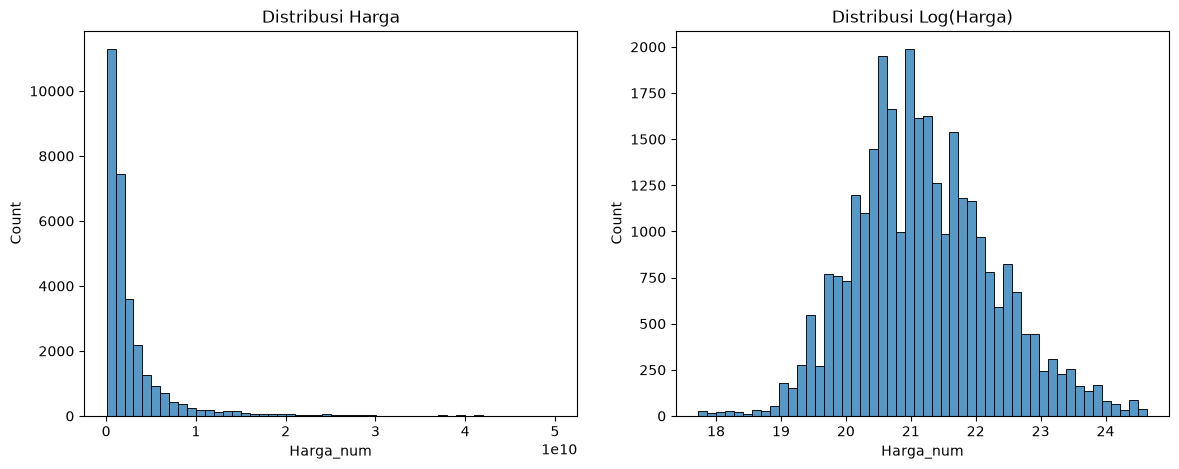

Skewness Harga: 4.407951388761584
Skewness Log(Harga): 0.3375438445560755


In [66]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(train_df['Harga_num'], bins=50, ax=axes[0])
axes[0].set_title('Distribusi Harga')

sns.histplot(np.log1p(train_df['Harga_num']), bins=50, ax=axes[1])
axes[1].set_title('Distribusi Log(Harga)')
plt.show()

print('Skewness Harga:', train_df['Harga_num'].skew())
print('Skewness Log(Harga):', np.log1p(train_df['Harga_num']).skew())

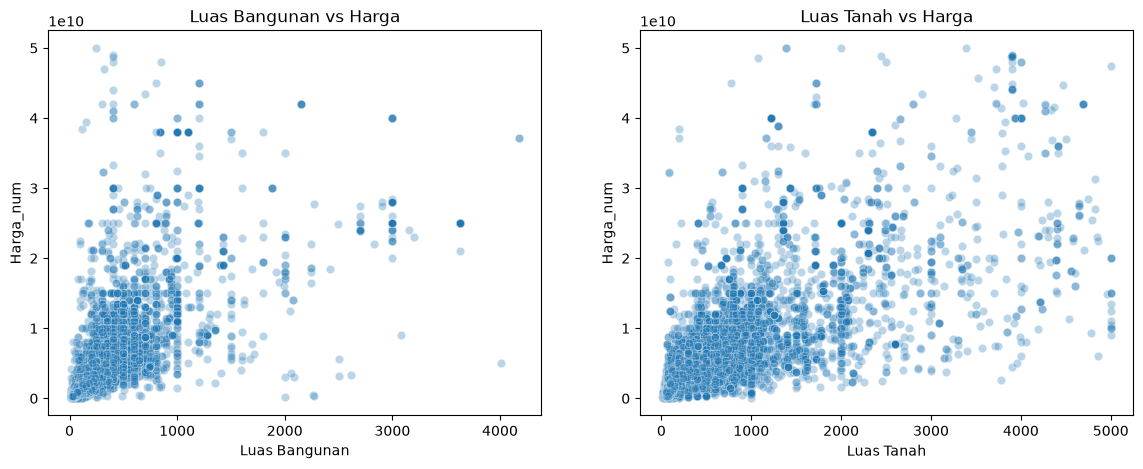

Harga_num        1.000000
Luas Tanah       0.780549
Luas Bangunan    0.745651
Kamar Tidur      0.291038
Kamar Mandi      0.384072
Garasi           0.561065
Name: Harga_num, dtype: float64


In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.scatterplot(data=train_df, x='Luas Bangunan', y='Harga_num', alpha=0.3, ax=axes[0])
axes[0].set_title('Luas Bangunan vs Harga')

sns.scatterplot(data=train_df, x='Luas Tanah', y='Harga_num', alpha=0.3, ax=axes[1])
axes[1].set_title('Luas Tanah vs Harga')
plt.show()

print(train_df[['Harga_num','Luas Tanah','Luas Bangunan','Kamar Tidur','Kamar Mandi','Garasi']].corr()['Harga_num'])

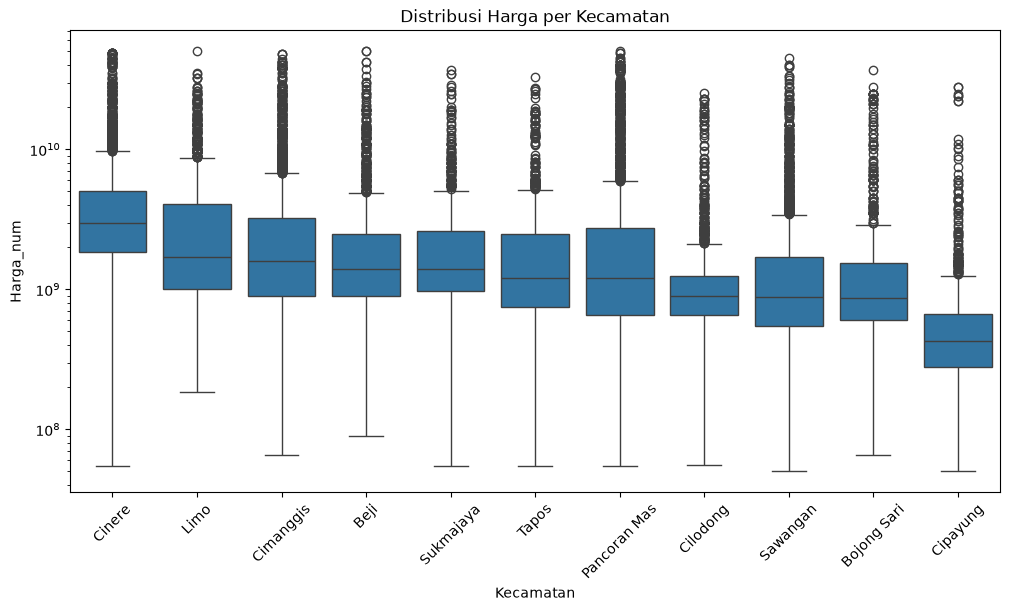

Kecamatan
Cinere          3.000000e+09
Limo            1.700000e+09
Cimanggis       1.600000e+09
Beji            1.400000e+09
Sukmajaya       1.400000e+09
Tapos           1.200000e+09
Pancoran Mas    1.200000e+09
Cilodong        9.000000e+08
Sawangan        8.800000e+08
Bojong Sari     8.600000e+08
Cipayung        4.250000e+08
Name: Harga_num, dtype: float64


In [68]:
plt.figure(figsize=(12,6))
order = train_df.groupby('Kecamatan')['Harga_num'].median().sort_values(ascending=False).index
sns.boxplot(data=train_df, x='Kecamatan', y='Harga_num', order=order)
plt.xticks(rotation=45)
plt.yscale('log')
plt.title('Distribusi Harga per Kecamatan')
plt.show()

print(train_df.groupby('Kecamatan')['Harga_num'].median().sort_values(ascending=False))

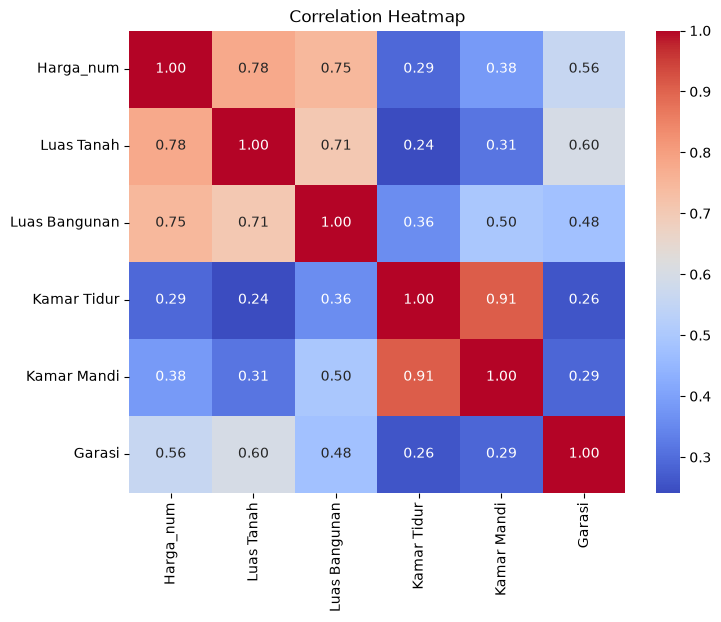

Garasi           37.472232
Kamar Mandi      14.392759
Kamar Tidur      10.533470
Luas Bangunan     9.154206
Luas Tanah        3.786347
dtype: float64


In [69]:
plt.figure(figsize=(8,6))
sns.heatmap(train_df[['Harga_num','Luas Tanah','Luas Bangunan','Kamar Tidur','Kamar Mandi','Garasi']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

missing_pct = train_df.isnull().mean().sort_values(ascending=False) * 100
print(missing_pct[missing_pct > 0])

## DIRECT MODELLING

✅ Parse Harga ke angka (wajib, karena ini target) — pakai parser sederhana, baris yang gagal parse (Agen/Ribu/dst) di-drop (gak ada pilihan lain, model butuh angka)
✅ Parse kolom lain ke angka apa adanya dari posisi kolom aslinya (gak di-reconstruct, biar ketahuan efeknya noise akibat shifting)
✅ Missing value diisi 0 sementara (bukan median/strategi canggih — Direct Modeling sengaja naive)
✅ Kecamatan di-label-encode mentah (38 kategori asli, gak di-mapping ke 11)
❌ Outlier TIDAK difilter
❌ Duplikat TIDAK dihapus

In [70]:
df_raw = pd.read_csv('../data/raw/Raw-Final-Rumah.csv')
train_raw, test_raw = train_test_split(df_raw, test_size=0.2, random_state=42)
train_raw = train_raw.reset_index(drop=True)
test_raw = test_raw.reset_index(drop=True)

def parse_harga_raw(x):
    try:
        x = str(x)
        if 'Miliar' in x:
            return float(x.replace('Miliar','').replace('Total','').replace(',','.').strip()) * 1e9
        elif 'Juta' in x:
            return float(x.replace('Juta','').replace('Total','').replace(',','.').strip()) * 1e6
        elif 'Ribu' in x:
            return float(x.replace('Ribu','').replace('Total','').replace(',','.').strip()) * 1e3
        elif 'Triliun' in x:
            return float(x.replace('Triliun','').replace('Total','').replace(',','.').strip()) * 1e12
        else:
            return np.nan
    except:
        return np.nan

def parse_num_raw(x):
    try:
        m = re.search(r'(\d+)', str(x))
        return float(m.group(1)) if m else np.nan
    except:
        return np.nan

for d in [train_raw, test_raw]:
    d['Harga_num'] = d['Harga'].apply(parse_harga_raw)
    for col in ['Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan']:
        d[col] = d[col].apply(parse_num_raw)

train_raw = train_raw.dropna(subset=['Harga_num']).reset_index(drop=True)
test_raw = test_raw.dropna(subset=['Harga_num']).reset_index(drop=True)

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
train_raw['Kecamatan_enc'] = le.fit_transform(train_raw['Kecamatan'])
test_raw['Kecamatan_enc'] = test_raw['Kecamatan'].map(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

feature_cols = ['Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan','Kecamatan_enc']
X_train_raw = train_raw[feature_cols].fillna(0)
y_train_raw = train_raw['Harga_num']
X_test_raw = test_raw[feature_cols].fillna(0)
y_test_raw = test_raw['Harga_num']

print(X_train_raw.shape, X_test_raw.shape)

(32087, 6) (8016, 6)


In [71]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(random_state=42),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42, n_jobs=-1),
}

results_direct = []
for name, model in models.items():
    model.fit(X_train_raw, y_train_raw)
    pred = model.predict(X_test_raw)
    results_direct.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test_raw, pred),
        'MAPE': mean_absolute_percentage_error(y_test_raw, pred),
        'R2': r2_score(y_test_raw, pred)
    })

results_direct_df = pd.DataFrame(results_direct)
print(results_direct_df)

               Model           MAE         MAPE        R2
0  Linear Regression  1.932820e+11   391.053477  0.020239
1              Ridge  1.932820e+11   391.053474  0.020239
2      Decision Tree  2.201574e+11    73.137805 -2.884215
3      Random Forest  2.866990e+11  1408.123167 -3.922724
4  Gradient Boosting  2.317988e+11  3386.658685 -1.768124
5            XGBoost  2.666045e+11   339.028639 -1.972221


# preprocess

# reset dulu boy biar test datanya ga asal asalan + enak dipakai di webnya

In [72]:
import re

def reconstruct_row(row):
    numbers, lt_val, lb_val = [], None, None
    for v in row:
        if pd.isna(v): continue
        v = str(v).strip()
        if v.startswith('LT'):
            m = re.search(r'(\d+)', v)
            if m: lt_val = int(m.group(1))
        elif v.startswith('LB'):
            m = re.search(r'(\d+)', v)
            if m: lb_val = int(m.group(1))
        else:
            m = re.search(r'(\d+)', v)
            if m: numbers.append(int(m.group(1)))
    kt = numbers[0] if len(numbers) > 0 else None
    km = numbers[1] if len(numbers) > 1 else None
    gr = numbers[2] if len(numbers) > 2 else None
    return pd.Series([kt, km, gr, lt_val, lb_val])

def parse_harga(x):
    x = str(x).replace('Total', '').strip()
    x = x.replace('Miliar', '').replace('Juta', 'JT').strip()
    if 'JT' in x:
        return float(x.replace('JT', '').replace(',', '.').strip()) * 1_000_000
    return float(x.replace(',', '.').strip()) * 1_000_000_000

kec_map = {
    'Rangkapanjaya': 'Pancoran Mas', 'Depok I': 'Pancoran Mas', 'Depok II': 'Pancoran Mas',
    'Margonda': 'Pancoran Mas',
    'Harjamukti': 'Cimanggis', 'Cibubur': 'Cimanggis', 'Mekarsari': 'Cimanggis',
    'Tugu': 'Cimanggis', 'Kelapa Dua': 'Cimanggis', 'Cisalak': 'Cimanggis',
    'Tirtajaya': 'Sukmajaya', 'Studio Alam': 'Sukmajaya', 'Grand Depok City': 'Sukmajaya',
    'Tanah Baru': 'Beji', 'Kukusan': 'Beji',
    'Pangkalan Jati': 'Limo', 'Krukut': 'Limo',
    'Cilangkap': 'Tapos', 'Sukatani': 'Tapos',
    'Cinangka': 'Sawangan', 'Pasir Putih': 'Sawangan',
    'Gandul': 'Cinere',
    'Citayam': 'Cipayung',
}
out_of_scope = ['Ciangsana', 'Kalimanggis', 'Babadan', 'Sumur Batu']

def clean_pipeline(df, is_train):
    df = df.copy()
    df = df[~df['Harga'].astype(str).str.contains('Agen|Ribu|Triliun|/m²|/m2|/ha', na=False)].copy()
    df['Harga_num'] = df['Harga'].apply(parse_harga)

    cols5 = ['Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan']
    df[cols5] = df[cols5].apply(reconstruct_row, axis=1)

    if is_train:
        df = df.drop_duplicates()

    df['Kecamatan'] = df['Kecamatan'].replace(kec_map)
    df = df[~df['Kecamatan'].isin(out_of_scope)]

    if 'Page' in df.columns:
        df = df.drop(columns=['Page'])

    df = df[df['Harga_num'].between(50_000_000, 50_000_000_000)]
    df = df[(df['Luas Tanah'].between(10, 5000)) | (df['Luas Tanah'].isna())]
    df = df[(df['Luas Bangunan'].between(10, 5000)) | (df['Luas Bangunan'].isna())]

    df = df.drop(columns=['Harga']).reset_index(drop=True)
    return df

df_full = pd.read_csv('../data/raw/Raw-Final-Rumah.csv')
train_split, test_split = train_test_split(df_full, test_size=0.2, random_state=42)
train_split = train_split.reset_index(drop=True)
test_split = test_split.reset_index(drop=True)

train_clean = clean_pipeline(train_split, is_train=True)
test_clean = clean_pipeline(test_split, is_train=False)

print(train_clean.shape, test_clean.shape)
print(train_clean.isnull().sum())

(30161, 7) (7805, 7)
Kamar Tidur       3177
Kamar Mandi       4341
Garasi           11302
Luas Tanah        1142
Luas Bangunan     2761
Kecamatan            0
Harga_num            0
dtype: int64


# imputasi dan encoding

In [73]:
median_per_kec = train_clean.groupby('Kecamatan')[['Kamar Tidur','Kamar Mandi','Luas Tanah','Luas Bangunan']].median()

def impute(df, median_ref):
    df = df.copy()
    df['Garasi'] = df['Garasi'].fillna(0)
    for col in ['Kamar Tidur','Kamar Mandi','Luas Tanah','Luas Bangunan']:
        df[col] = df.apply(lambda r: median_ref.loc[r['Kecamatan'], col] if pd.isna(r[col]) else r[col], axis=1)
    return df

train_imputed = impute(train_clean, median_per_kec)
test_imputed = impute(test_clean, median_per_kec)

print(train_imputed.isnull().sum())
print(test_imputed.isnull().sum())

Kamar Tidur      0
Kamar Mandi      0
Garasi           0
Luas Tanah       0
Luas Bangunan    0
Kecamatan        0
Harga_num        0
dtype: int64
Kamar Tidur      0
Kamar Mandi      0
Garasi           0
Luas Tanah       0
Luas Bangunan    0
Kecamatan        0
Harga_num        0
dtype: int64


In [74]:
kec_target_map = train_imputed.groupby('Kecamatan')['Harga_num'].mean()

train_imputed['Kecamatan_enc'] = train_imputed['Kecamatan'].map(kec_target_map)
test_imputed['Kecamatan_enc'] = test_imputed['Kecamatan'].map(kec_target_map)

print(train_imputed[['Kecamatan','Kecamatan_enc']].drop_duplicates().sort_values('Kecamatan_enc', ascending=False))

       Kecamatan  Kecamatan_enc
14        Cinere   4.408976e+09
17          Limo   3.570865e+09
1      Cimanggis   3.405902e+09
23  Pancoran Mas   3.373203e+09
0           Beji   2.708752e+09
21         Tapos   2.434134e+09
2      Sukmajaya   2.392005e+09
4    Bojong Sari   2.191283e+09
12      Sawangan   1.794996e+09
7       Cilodong   1.441882e+09
20      Cipayung   7.937084e+08


In [75]:
feature_cols_clean = ['Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan','Kecamatan_enc']

X_train_clean = train_imputed[feature_cols_clean]
y_train_clean = train_imputed['Harga_num']
X_test_clean = test_imputed[feature_cols_clean]
y_test_clean = test_imputed['Harga_num']

print(X_train_clean.shape, X_test_clean.shape)

(30161, 6) (7805, 6)


# modelling

In [76]:
models_clean = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(random_state=42),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42, n_jobs=-1),
}

results_clean = []
for name, model in models_clean.items():
    model.fit(X_train_clean, y_train_clean)
    pred = model.predict(X_test_clean)
    results_clean.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test_clean, pred),
        'MAPE': mean_absolute_percentage_error(y_test_clean, pred),
        'R2': r2_score(y_test_clean, pred)
    })

results_clean_df = pd.DataFrame(results_clean)
print(results_clean_df)

d:\kuliah\SEMESTER7\bengkod\early-bird\depok-house-price-prediction\env-depok-house\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.1911559889563194e-18.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


               Model           MAE      MAPE        R2
0  Linear Regression  2.486321e+09  1.883891  0.044063
1              Ridge  1.099610e+09  0.587485  0.706983
2      Decision Tree  6.907015e+08  0.311207  0.788990
3      Random Forest  6.186007e+08  0.297417  0.855153
4  Gradient Boosting  9.393866e+08  0.437851  0.781582
5            XGBoost  8.017765e+08  0.360609  0.814633


In [77]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

for name in ['Linear Regression', 'Ridge']:
    model = models_clean[name]
    model.fit(X_train_scaled, y_train_clean)
    pred = model.predict(X_test_scaled)
    idx = results_clean_df[results_clean_df['Model']==name].index[0]
    results_clean_df.loc[idx, 'MAE'] = mean_absolute_error(y_test_clean, pred)
    results_clean_df.loc[idx, 'MAPE'] = mean_absolute_percentage_error(y_test_clean, pred)
    results_clean_df.loc[idx, 'R2'] = r2_score(y_test_clean, pred)

print(results_clean_df)

               Model           MAE      MAPE        R2
0  Linear Regression  1.099610e+09  0.587484  0.706983
1              Ridge  1.099611e+09  0.587489  0.706981
2      Decision Tree  6.907015e+08  0.311207  0.788990
3      Random Forest  6.186007e+08  0.297417  0.855153
4  Gradient Boosting  9.393866e+08  0.437851  0.781582
5            XGBoost  8.017765e+08  0.360609  0.814633


# feature selection

In [78]:
rf_final = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_final.fit(X_train_clean, y_train_clean)

importance = pd.Series(rf_final.feature_importances_, index=feature_cols_clean).sort_values(ascending=False)
print(importance)

Luas Tanah       0.772404
Luas Bangunan    0.135378
Kecamatan_enc    0.051370
Kamar Tidur      0.017077
Kamar Mandi      0.014141
Garasi           0.009629
dtype: float64


In [79]:
X_train_fs = X_train_clean.copy()
X_test_fs = X_test_clean.copy()

X_train_fs['Total Kamar'] = X_train_fs['Kamar Tidur'] + X_train_fs['Kamar Mandi']
X_test_fs['Total Kamar'] = X_test_fs['Kamar Tidur'] + X_test_fs['Kamar Mandi']

X_train_fs = X_train_fs.drop(columns=['Kamar Tidur','Kamar Mandi'])
X_test_fs = X_test_fs.drop(columns=['Kamar Tidur','Kamar Mandi'])

rf_fs = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_fs.fit(X_train_fs, y_train_clean)
pred_fs = rf_fs.predict(X_test_fs)

print('R2 sebelum FS:', 0.855153)
print('R2 setelah FS:', r2_score(y_test_clean, pred_fs))
print('MAE setelah FS:', mean_absolute_error(y_test_clean, pred_fs))
print('MAPE setelah FS:', mean_absolute_percentage_error(y_test_clean, pred_fs))

R2 sebelum FS: 0.855153
R2 setelah FS: 0.852737198935853
MAE setelah FS: 624197061.4481518
MAPE setelah FS: 0.299855139102753


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_clean, y_train_clean)

print('Best params:', rf_search.best_params_)
print('Best CV R2:', rf_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 20}
Best CV R2: 0.8426589565031495
